# core

> BFrame

In [ ]:
#| default_exp core

In [ ]:
#| hide
from nbdev.showdoc import *

In [ ]:
#| export
from fastcore.all import *
from basedpl import *
from math import inf

# BFrame

In [ ]:
#| export
@patch
def _classify(self:Array): 
    self.__class__ = FunctionArray if self._inner.holds_functions else type(self)

class BFrame(Array): ...

In [ ]:
test_frame = BFrame(dict(col=[1,2,3]))
test_frame

┌→────────────┐
│ col:┌→────┐ │
│     │1 2 3│ │
│     └ₓ────┘ │
└∊────────────┘

In [ ]:
test_eq(BFrame, type(test_frame))

In [ ]:
#| export
@patch
def __getitem__(self:BFrame, i): return BFrame(Array.__getitem__(self, i))

In [ ]:
test_eq(BFrame, type(test_frame[0]))

## Reading and writing

### CSV

In [ ]:
#| export
@patch(cls_method=True)
def read_csv(cls:BFrame, path, **kwargs): return cls(csv(nget(path, **kwargs)))

In [ ]:
bf = BFrame.read_csv("../data/toy.csv", encoding="UTF-8")
test_eq(BFrame, type(bf))
bf.df.head(2)

,Number,City,Gender,Age,Income,Illness
0,1,Dallas,Male,41,40367.0,No
1,2,Dallas,Male,54,45084.0,No


In [ ]:
#| export
@patch
def save_csv(self:BFrame, path): return nput(path, csv.undo(self))

In [ ]:
# bf.save_csv("../data/save_test.csv");

## Selection

In [ ]:
#| export
@patch
def head(self:BFrame, n=5): return BFrame(take.each(n, self))

In [ ]:
test_eq(BFrame, type(bf.head()))
head = bf.head(100)
head.head(2).df

,Number,City,Gender,Age,Income,Illness
0,1,Dallas,Male,41,40367.0,No
1,2,Dallas,Male,54,45084.0,No


In [ ]:
#| export
@patch
def tail(self:BFrame, n=5): return BFrame(take.each(-n, self))

In [ ]:
test_eq(BFrame, type(bf.tail()))
bf.tail(2).df

,Number,City,Gender,Age,Income,Illness
0,149999,Austin,Male,25,111878.0,No
1,150000,Austin,Female,37,87251.0,No


## Groupby

In [ ]:
#| export
agg = fn('{(↑⍺)⍠0 ⍵}').rank([0, inf])
gfan = agg.left
rfan = agg.rank([inf, 2]).left


In [ ]:
display(agg)
display(gfan)
display(rfan)

{(↑⍺)⍠0 ⍵}⍤[0 ∞]

↣(□, {(↑⍺)⍠0 ⍵}⍤[0 ∞])

↣(□, {(↑⍺)⍠0 ⍵}⍤[0 ∞]⍤[∞ 2])

In [ ]:
#| export
@patch
def matrix(self:BFrame, cols) -> Array: return transpose(mix(self[listify(cols)]))

In [ ]:
head.matrix("Age")[:2]

┌→──┐
↓Age│
│ 41│
│ 54│
└ₓ──┘

In [ ]:
#| export
@patch
def groupby(self:BFrame, by, cols, **aggs):
    by,cols = self.matrix(by),self.matrix(cols)
    res = right.after(gfan(aggs)).key(by, cols)
    return BFrame(keyed(unique(by)[:, by.keys[1][0]], res))

In [ ]:
MEAN = add.reduce / tally
RMSE = MEAN.under(square)
fn_dict=dict(mean=MEAN, rmse=RMSE)
fn_dict

{'mean': +/÷≢, 'rmse': (+/÷≢)@⊼}

In [ ]:
head.groupby("Gender", "Income", mean=MEAN).df

,,Income
Male,mean,48301.425926
Female,mean,39739.369565


In [ ]:
head.groupby("Gender", ["Age", "Income"], **fn_dict).df

Age        Income
Male   mean  44.574074  48301.425926
       rmse  45.669708  49632.106391
Female mean  45.304348  39739.369565
       rmse  46.734681  40738.658528

## Rolling
`windows` docs with arg explanations: https://answerdotai.github.io/basedpl/glyphs/up-down-arrow.html

In [ ]:
#| export
@patch
def rolling(self:BFrame, cols, size, edge="fill", step=1, fill=0, **aggs):
    return BFrame(rfan(aggs)(windows(self.matrix(cols), size=size, edge=edge, step=step, fill=fill)))


In [ ]:
ts = BFrame(dict(price=[5,4.3,4.1,2,10,20,15,25]))
ts.rolling("price", size=3, mean=MEAN).df

,,price
0,mean,3.100000
1,mean,4.466667
2,mean,3.466667
3,mean,5.366667
4,mean,10.666667
5,mean,15.000000
6,mean,20.000000
7,mean,13.333333


In [ ]:
ts.rolling("price", size=5, step=2, mean=MEAN, rmse=RMSE).df

price
0 mean   2.680000
  rmse   3.472751
1 mean   5.080000
  rmse   5.732364
2 mean  10.220000
  rmse  12.213190
3 mean  14.000000
  rmse  16.431677

## Viz

In [ ]:
#| export
@patch
def plot(self:BFrame, **kwargs): return plot(self, **kwargs)

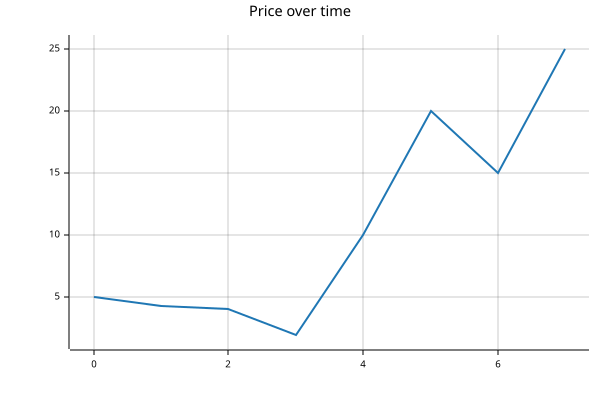

In [ ]:
BFrame(dict(price=[5,4.3,4.1,2,10,20,15,25])).plot(mark="line", title="Price over time")

In [ ]:
#| export
@patch
def hist_input(self:BFrame, n:int):
    lo,hi = Array([minimum.reduce_first, maximum.reduce_first])(self)
    w = (hi-lo)/n
    starts = lo+w*iota(n)
    return BFrame(dict(x=starts+w/2,
        count=take(n, where.undo(interval_index(starts[1:], self)))))

In [ ]:
income = head["Income"]
income.hist_input(2)

┌→────────────────────────────────────┐
│ x:┌→────────────────┐ count:┌→────┐ │
│   │29292.75 55542.25│       │43 57│ │
│   └~────────────────┘       └ₓ────┘ │
└∊────────────────────────────────────┘

In [ ]:
#| export
@patch
def hist(self:BFrame, n=50, **kwargs): return self.hist_input(n).plot(mark="bar", **kwargs)

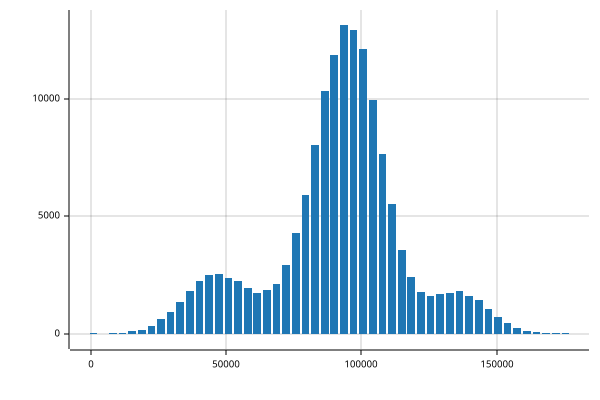

In [ ]:
bf["Income"].hist()

In [ ]:
#| hide
import nbdev; nbdev.nbdev_export()